# Audio and Voice Model (Member 3: Fadhili)

**Goal of this section:** turn voice recordings into numbers a model can learn from, then build a
*voiceprint verification* model that answers: **"Is this one of our approved members speaking, and who?"**
In the full system this is the second security check, after face recognition and before the product prediction is allowed.

**Data:** 4 members (armstrong, ayomide, diane, fadhili) x 2 phrases ("Yes, approve", "Confirm transaction") = 8 recordings.
They were sent as WhatsApp voice notes and `.wav` files, then converted to 16 kHz mono `.wav`.

**Pipeline:** load and convert -> visualise -> clean -> augment (6 ways) -> extract features -> `audio_features.csv` -> train and evaluate -> verify.

> Run from the folder that contains this notebook and `audio_pipeline.py`, `voice_model.py`.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, librosa, librosa.display, soundfile as sf
import matplotlib.pyplot as plt
from IPython.display import Audio, display
import audio_pipeline as ap
import voice_model as vm
%matplotlib inline

ROOT = Path.cwd()
WAV = ROOT / "converted"
SR = ap.SR
files = sorted(WAV.glob("*.wav"))
rows = []
for f in files:
    y, _ = librosa.load(f, sr=SR)
    rows.append({"file": f.name, "seconds": round(len(y)/SR, 2), "peak": round(float(abs(y).max()), 3)})
pd.DataFrame(rows)

,file,seconds,peak
0,armstrong_confirm_transaction.wav,2.72,0.687
1,armstrong_yes_approve.wav,2.05,0.585
2,ayomide_confirm_transaction.wav,4.52,0.718
3,ayomide_yes_approve.wav,2.39,0.623
4,diane_confirm_transaction.wav,1.66,0.411
5,diane_yes_approve.wav,1.64,0.797
6,fadhili_confirm_transaction.wav,2.85,1.000
7,fadhili_yes_approve.wav,2.39,0.649


## 1. Loading the recordings

All 8 files are 1.6 - 4.5 seconds long. One file has a peak of 1.0, meaning part of the signal hit the maximum level (clipping).
We find out why in the next section.

## 2. Waveforms and spectrograms for every member

**How to read them.** The *waveform* (top) shows loudness over time: each bump is a syllable and flat stretches are silence.
The *spectrogram* (bottom) shows which pitches are present over time (brighter = louder). The horizontal stripes at the
bottom (below ~1,000 Hz) are the voice's pitch and its harmonics, which are a large part of what makes a voice recognisable.

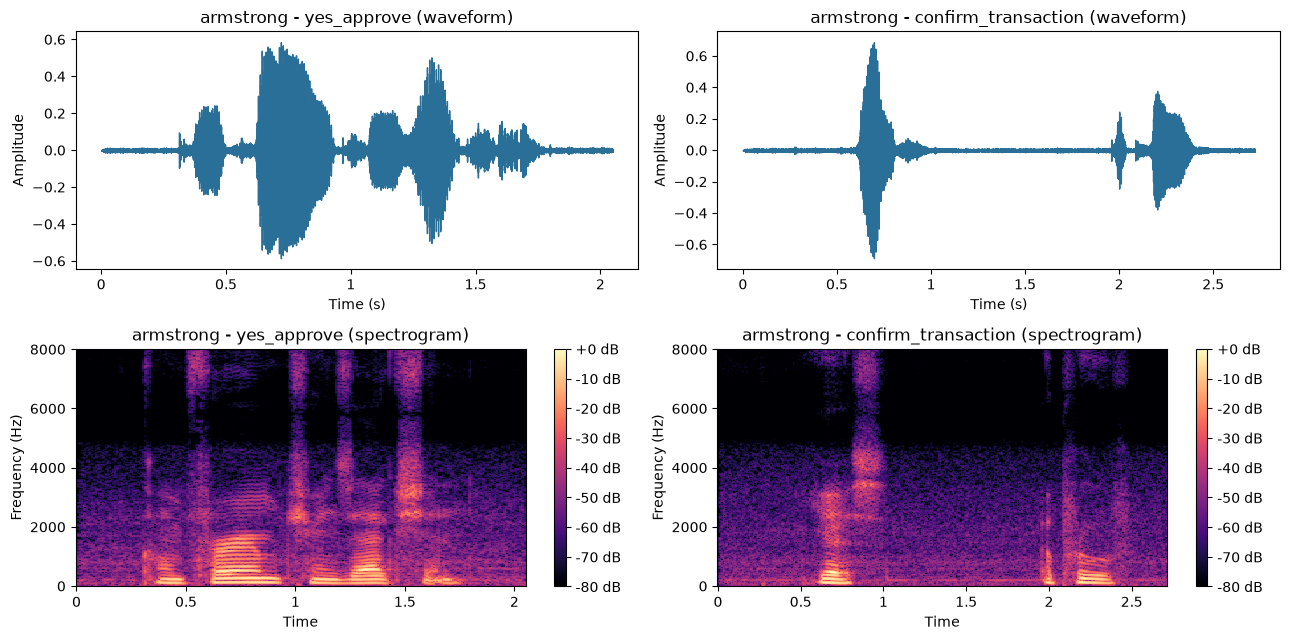

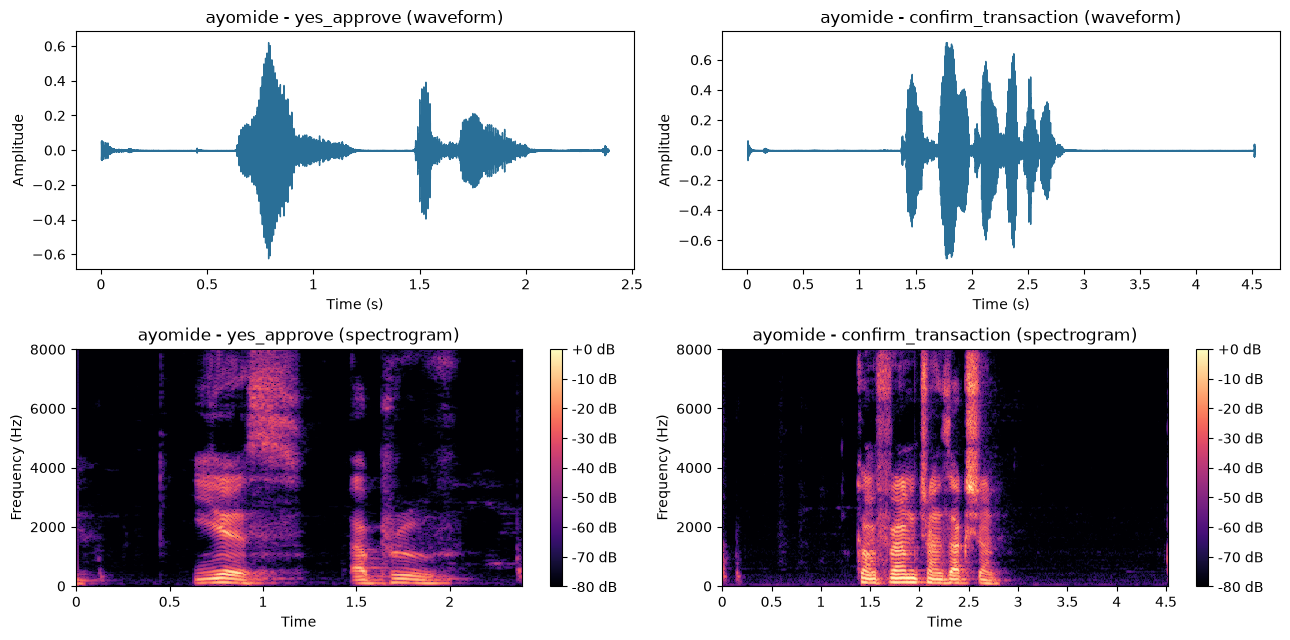

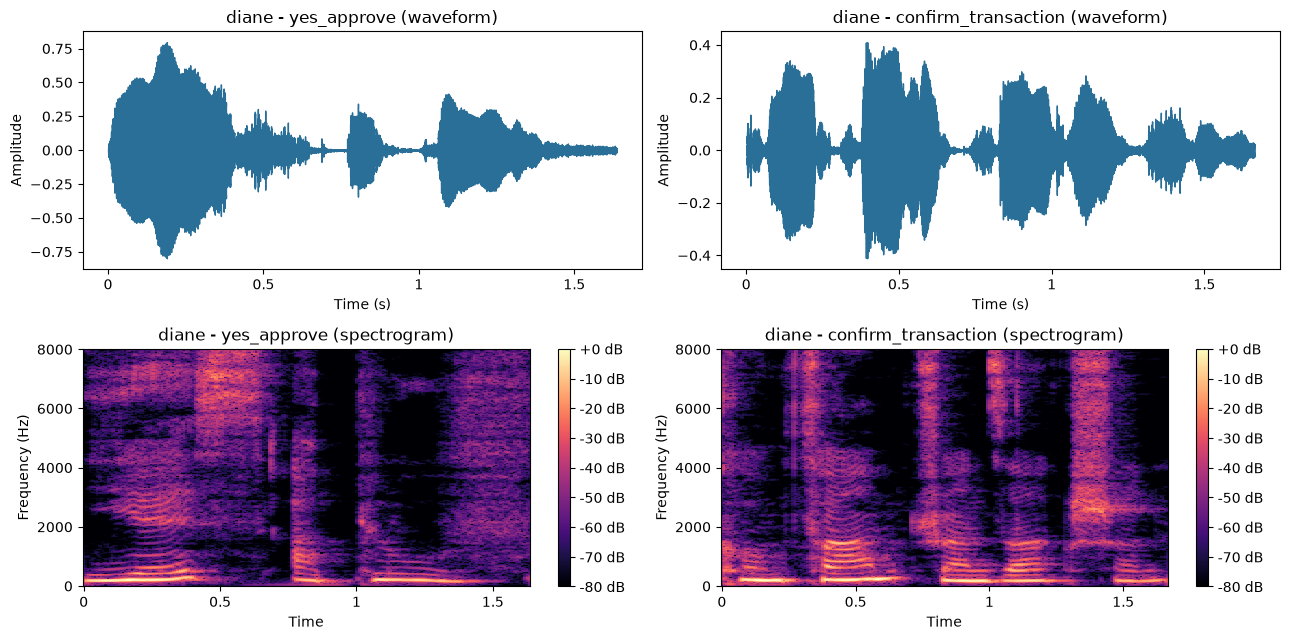

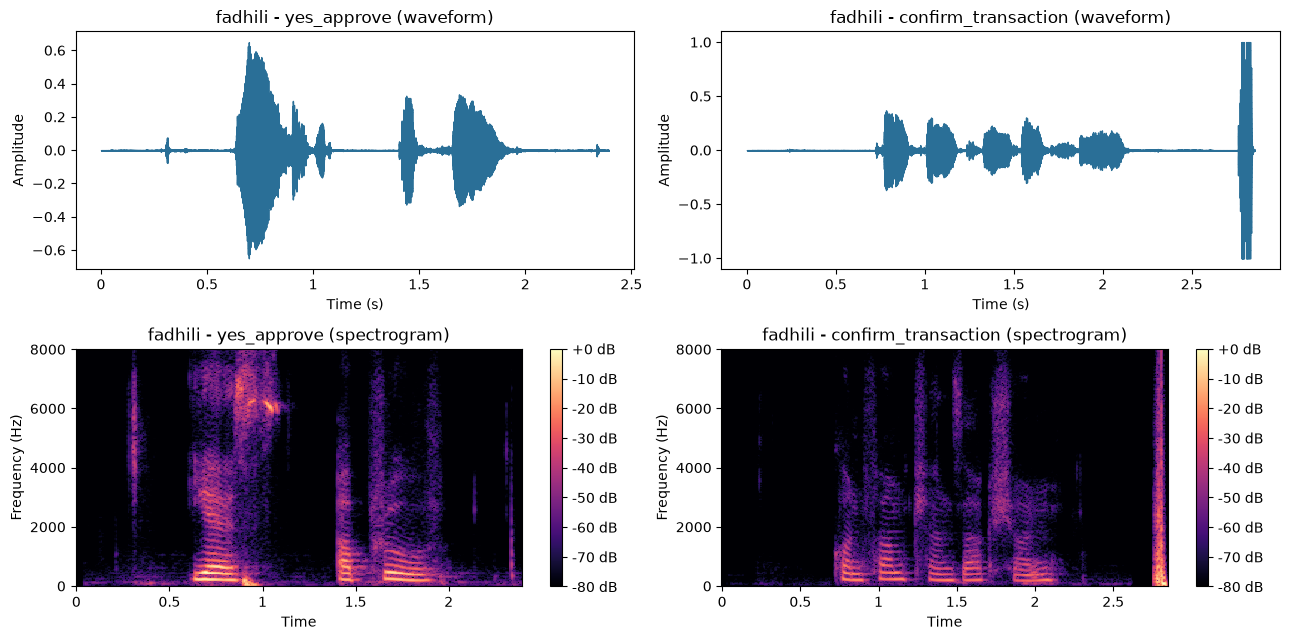

In [2]:
def show_member(m):
    fig, ax = plt.subplots(2, 2, figsize=(13, 6.5))
    for col, ph in enumerate(["yes_approve", "confirm_transaction"]):
        y, sr = librosa.load(WAV / f"{m}_{ph}.wav", sr=SR)
        librosa.display.waveshow(y, sr=sr, ax=ax[0, col], color="#2a6f97")
        ax[0, col].set(title=f"{m} - {ph} (waveform)", xlabel="Time (s)", ylabel="Amplitude")
        S = librosa.amplitude_to_db(np.abs(librosa.stft(y, n_fft=512, hop_length=128)), ref=np.max)
        im = librosa.display.specshow(S, sr=sr, hop_length=128, x_axis="time", y_axis="hz", ax=ax[1, col], cmap="magma")
        ax[1, col].set(title=f"{m} - {ph} (spectrogram)", ylabel="Frequency (Hz)")
        fig.colorbar(im, ax=ax[1, col], format="%+2.0f dB")
    fig.tight_layout(); plt.show()

for m in ["armstrong", "ayomide", "diane", "fadhili"]:
    show_member(m)

### Interpretation

| Member | Speech pitch (rough) | What stands out |
|---|---|---|
| Armstrong | low (~100-113 Hz) | Energy stops near 4.8 kHz: typical of WhatsApp compression. Otherwise clean. |
| Ayomide | low (~107 Hz) | The "confirm" file has ~1.4 s of silence before speech and ~1.5 s after, with small clicks at the very start and end. |
| Diane | higher (~185-206 Hz) | Speech starts at 0.0 s (start may be clipped). Loudest speaker, and the spectrogram shows the most background noise. |
| Fadhili | mid (~135-197 Hz) | In "confirm" there is a loud click at ~2.8 s that hits the maximum level. It is the tap on the stop button, not speech. |

*Pitch values are automatic estimates, so treat them as "low" versus "higher", not exact numbers.*

**What this means for the model**
1. A big pitch gap (Diane versus the others) makes a voice easy to tell apart; voices close in pitch are harder.
2. Each phone and each WhatsApp compression leaves its own "signature", so the model may partly learn the *recording setup*, not only the voice. This is a limitation.
3. Silence and clicks distort averaged features, so they must be removed before feature extraction.

## 3. Cleaning

`clean()` in `audio_pipeline.py` does three things: (1) cuts a clipped click in the second half of a clip, (2) trims leading and
trailing silence, (3) normalises the peak volume to 0.9, so loudness (which depends on the phone) matters less.

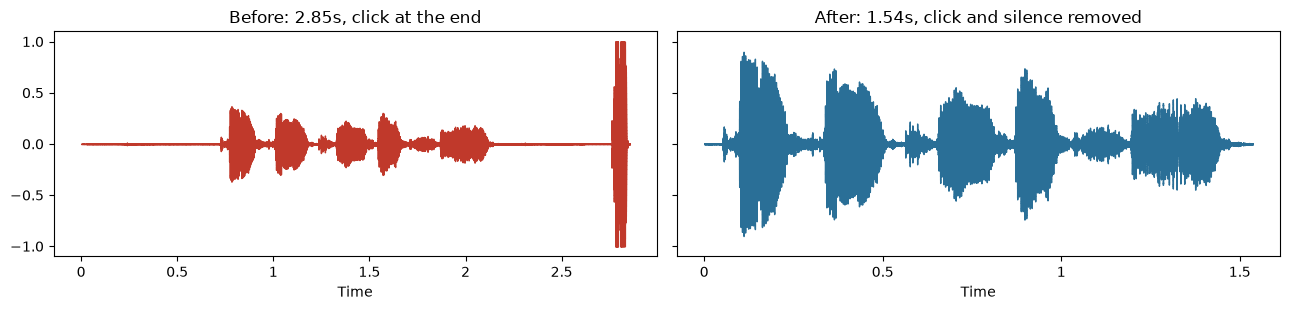

Clipped samples before: 326 | after: 0


In [3]:
y_raw, _ = librosa.load(WAV / "fadhili_confirm_transaction.wav", sr=SR)
y_clean = ap.clean(y_raw)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.2), sharey=True)
librosa.display.waveshow(y_raw, sr=SR, ax=ax[0], color="#c0392b"); ax[0].set_title(f"Before: {len(y_raw)/SR:.2f}s, click at the end")
librosa.display.waveshow(y_clean, sr=SR, ax=ax[1], color="#2a6f97"); ax[1].set_title(f"After: {len(y_clean)/SR:.2f}s, click and silence removed")
plt.tight_layout(); plt.show()
print("Clipped samples before:", int((abs(y_raw) >= 0.99).sum()), "| after:", int((abs(y_clean) >= 0.99).sum()))

## 4. Augmentation (6 versions per recording)

With only 8 recordings, a model has very little to learn from. Augmentation makes realistic variations of each clip:

| Name | What it simulates |
|---|---|
| `pitch_up` / `pitch_down` | the same person speaking slightly higher / lower (+/-1.5 semitones) |
| `stretch_fast` / `stretch_slow` | speaking 15% faster / slower (pitch unchanged) |
| `noise_20db` / `noise_10db` | a quiet room / a noisy room (random noise at 20 dB / 10 dB signal-to-noise) |

Each recording becomes 1 original + 6 augmented copies = **7 rows** (the assignment asks for at least 2 augmentations).

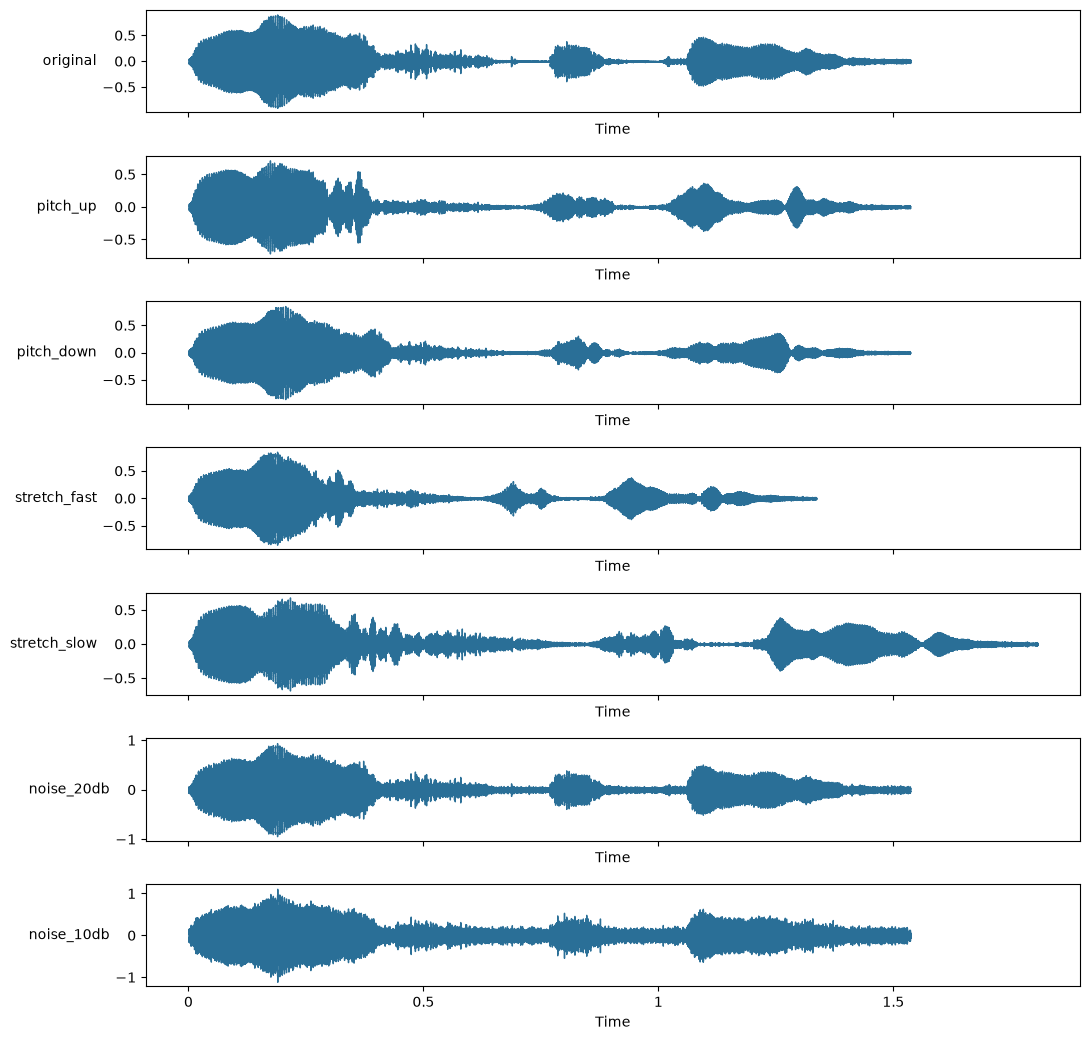

original


pitch_up


stretch_slow


noise_10db


In [4]:
y, _ = librosa.load(WAV / "diane_yes_approve.wav", sr=SR)
y = ap.clean(y)
versions = {"original": y} | {k: fn(y) for k, fn in ap.AUGMENTATIONS.items()}
fig, ax = plt.subplots(len(versions), 1, figsize=(11, 1.5*len(versions)), sharex=True)
for a, (name, sig) in zip(ax, versions.items()):
    librosa.display.waveshow(sig, sr=SR, ax=a, color="#2a6f97"); a.set_ylabel(name, rotation=0, ha="right", va="center")
plt.tight_layout(); plt.show()
for name in ["original", "pitch_up", "stretch_slow", "noise_10db"]:
    print(name); display(Audio(versions[name], rate=SR))

## 5. Feature extraction -> `audio_features.csv`

Every clip becomes one row of numbers:
- **MFCCs** (13 coefficients, mean and std = 26 columns): a compact description of the voice's tone colour (the shape of the vocal tract).
- **Spectral roll-off** (mean, std): the frequency below which 85% of the sound energy sits (low = dark/bassy, high = bright/noisy).
- **Energy** (RMS mean, std, total): how strong the signal is.
- Extras: spectral centroid, bandwidth, zero-crossing rate, duration.

In [5]:
df = pd.read_csv("audio_features.csv")
print(df.shape, "| missing values:", int(df.isna().sum().sum()))
df.head(7).round(3)

(56, 39) | missing values: 0


,clip_id,speaker,phrase,augmentation,mfcc1_mean,mfcc1_std,mfcc2_mean,mfcc2_std,mfcc3_mean,mfcc3_std,...,mfcc13_std,rolloff_mean,rolloff_std,energy_mean,energy_std,energy_total,centroid_mean,bandwidth_mean,zcr_mean,duration_s
0,armstrong_confirm_transaction,armstrong,confirm_transaction,original,-289.630,64.190,126.848,44.649,-26.515,16.295,...,5.109,2527.218,930.729,0.056,0.075,277.785,1360.247,1295.878,0.113,1.952
1,armstrong_confirm_transaction,armstrong,confirm_transaction,pitch_up,-312.760,66.200,123.312,45.020,-25.691,14.891,...,7.115,2682.586,987.272,0.038,0.049,124.497,1386.148,1244.773,0.123,1.952
2,armstrong_confirm_transaction,armstrong,confirm_transaction,pitch_down,-320.781,67.972,130.118,43.720,-21.213,15.495,...,7.886,2259.577,862.285,0.047,0.065,206.820,1179.367,1132.497,0.093,1.952
3,armstrong_confirm_transaction,armstrong,confirm_transaction,stretch_fast,-315.474,70.107,124.932,42.686,-22.424,15.624,...,4.618,2500.579,937.908,0.045,0.061,158.951,1328.692,1303.866,0.107,1.697
4,armstrong_confirm_transaction,armstrong,confirm_transaction,stretch_slow,-319.358,66.911,123.298,44.752,-21.587,15.880,...,5.262,2556.641,959.412,0.039,0.054,163.806,1354.616,1315.115,0.114,2.296
5,armstrong_confirm_transaction,armstrong,confirm_transaction,noise_20db,-188.606,40.584,39.358,34.448,14.452,14.094,...,3.704,5651.966,1456.983,0.059,0.073,281.151,2930.484,2261.082,0.298,1.952
6,armstrong_confirm_transaction,armstrong,confirm_transaction,noise_10db,-106.929,25.185,16.151,24.207,10.363,12.235,...,3.372,6443.800,629.621,0.071,0.067,305.798,3475.449,2362.552,0.372,1.952


In [6]:
df.groupby("speaker")[["rolloff_mean", "energy_mean", "centroid_mean", "mfcc1_mean", "mfcc2_mean"]].mean().round(2)

,rolloff_mean,energy_mean,centroid_mean,mfcc1_mean,mfcc2_mean
speaker,,,,,
armstrong,3369.16,0.08,1739.79,-223.08,105.89
ayomide,4458.70,0.05,2346.72,-302.53,59.22
diane,4531.90,0.16,2425.00,-190.68,45.20
fadhili,3795.14,0.11,2013.00,-212.46,85.57


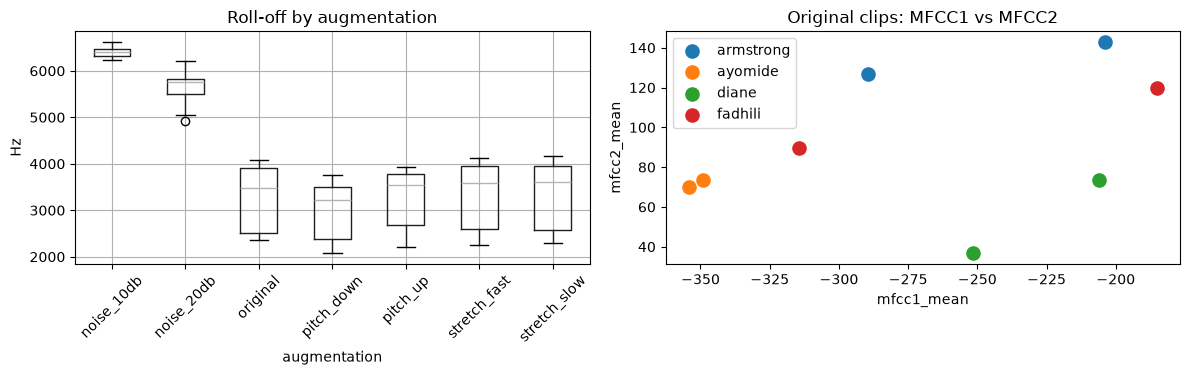

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df.boxplot(column="rolloff_mean", by="augmentation", ax=ax[0], rot=45); ax[0].set_title("Roll-off by augmentation"); ax[0].set_ylabel("Hz")
orig = df[df.augmentation == "original"]
for s, g in orig.groupby("speaker"):
    ax[1].scatter(g.mfcc1_mean, g.mfcc2_mean, s=90, label=s)
ax[1].set(title="Original clips: MFCC1 vs MFCC2", xlabel="mfcc1_mean", ylabel="mfcc2_mean"); ax[1].legend()
plt.suptitle(""); plt.tight_layout(); plt.show()

**Reading the charts.** Noisy copies (`noise_10db`, `noise_20db`) have a much higher roll-off than clean ones
(e.g. ~2,500 Hz -> ~6,400 Hz), because random noise spreads energy over all frequencies. That is expected, and it forces the model
to cope with clean and noisy input. In the right plot, each speaker's two recordings sit relatively close together, and that is why a model can work at all.

## 6. Voiceprint verification model

**Task:** given a clip, predict which of the 4 members is speaking. It is **accepted** only if the model's confidence reaches a threshold;
otherwise it is **rejected** as an unauthorized voice.

**Honest testing (leave-one-recording-out).** We hold out one original recording *and all its augmented copies*, train on the other 7 recordings,
and test on the held-out one. We repeat for all 8. This stops the model from "cheating" by seeing near-copies of the test clip during training.
Because each person has only 2 recordings, the model is tested on a *phrase it never heard from that person*.

**Metrics:** accuracy, macro F1, and log-loss (the "loss"; lower is better, 0 is perfect).

In [8]:
df, feats = vm.load_features()
res = vm.cross_validate(df, feats)
metrics = pd.DataFrame([{"model": n, **r[0]} for n, r in res.items()]).round(3)
metrics

,model,accuracy,f1_macro,log_loss
0,LogisticRegression,0.875,0.867,0.467
1,RandomForest,0.750,0.650,1.049


In [9]:
clips = sorted(df.clip_id.unique())
_, yt, yp, conf = res["LogisticRegression"]
pd.DataFrame({"recording": clips, "true": yt, "predicted": yp, "confidence": conf.round(2), "correct": [a == b for a, b in zip(yt, yp)]})

,recording,true,predicted,confidence,correct
0,armstrong_confirm_transaction,armstrong,armstrong,0.95,True
1,armstrong_yes_approve,armstrong,armstrong,0.62,True
2,ayomide_confirm_transaction,ayomide,ayomide,0.68,True
3,ayomide_yes_approve,ayomide,ayomide,0.95,True
4,diane_confirm_transaction,diane,diane,0.86,True
5,diane_yes_approve,diane,diane,0.78,True
6,fadhili_confirm_transaction,fadhili,fadhili,0.54,True
7,fadhili_yes_approve,fadhili,diane,0.54,False


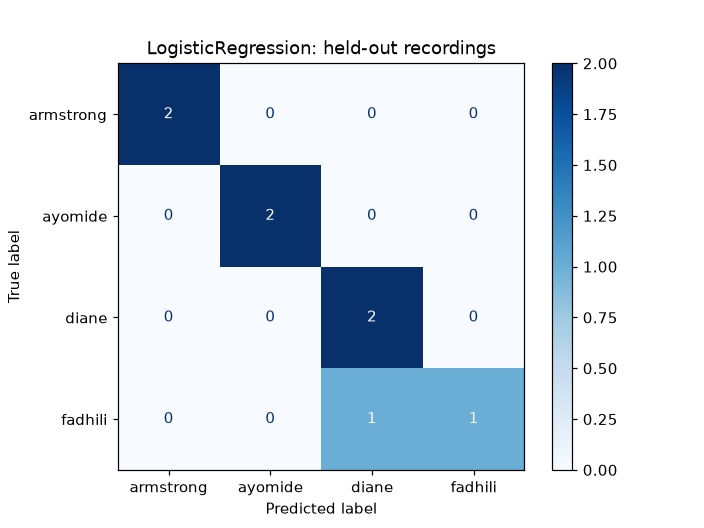

In [10]:
from IPython.display import Image
Image("plots/voice_confusion_matrix.png")

### Results

- **Logistic Regression is better on every metric** (accuracy, F1, log-loss) and was selected. Random Forest needs more data than 8 recordings.
- It identified **7 of 8** held-out recordings. The one miss was Fadhili's "Yes, approve", predicted as Diane; Fadhili's recordings also had the lowest confidence (0.54).

### Rejecting unauthorized voices

The accept threshold is chosen by comparing confidence on genuine members to confidence on people the model has **not** learned
(each member left out in turn, plus 4 text-to-speech voices from outside the group).

In [11]:
import joblib
b = joblib.load("models/voice_model.joblib")
print("model:", b["name"], "| accept threshold:", round(b["threshold"], 2))
for p in ["raw/diane_yes_approve.wav", "raw/fadhili_confirm_transaction.ogg",
          "unauthorized/stranger_tts1.wav", "unauthorized/stranger_tts2.wav",
          "unauthorized/stranger_tts3.mp3", "unauthorized/stranger_tts4.mp3"]:
    ok, who, c = vm.verify(p)
    print(f"{p:42s} -> {'ACCEPTED' if ok else 'REJECTED':8s} closest={who:9s} confidence={c:.2f}")

model: LogisticRegression | accept threshold: 0.76


raw/diane_yes_approve.wav                  -> ACCEPTED closest=diane     confidence=1.00
raw/fadhili_confirm_transaction.ogg        -> ACCEPTED closest=fadhili   confidence=0.99
unauthorized/stranger_tts1.wav             -> REJECTED closest=fadhili   confidence=0.72


unauthorized/stranger_tts2.wav             -> REJECTED closest=diane     confidence=0.59
unauthorized/stranger_tts3.mp3             -> REJECTED closest=fadhili   confidence=0.69
unauthorized/stranger_tts4.mp3             -> REJECTED closest=diane     confidence=0.48


## 7. Limitations and conclusions

- **Very little data:** 8 recordings from 4 people. Augmentation helps but adds no new voices.
- **Members are recognised well (7 of 8), but accepting members and rejecting strangers pull against each other.** With the chosen threshold (0.76),
  about 50% of *held-out* genuine recordings would be rejected, while about 17% of strangers get accepted. The threshold was tuned on only 12 stranger samples, so these figures are rough.
- **The demo above flatters the model:** the final model was trained on the members' own recordings, so those clips score 0.97 - 1.00 and are accepted easily.
  The honest estimate of how it treats a *new* recording of a member is the leave-one-recording-out table in section 6.
- **Recording setup leaks in:** different phones and WhatsApp compression change the sound, so the model may partly recognise the microphone.
- **Training pipeline sees the same people it tests:** a real system needs many more samples per person, in different rooms, to be secure.

**Conclusion.** Verification works as a proof of concept inside the multimodal flow (face -> voice -> prediction), but it should be treated as
a *demonstration*, not a secure voice lock. The main fix is collecting 10+ recordings per person.

**Files from this section:** `audio_features.csv`, `voice_model.py`, `models/voice_model.joblib`, `models/voice_metrics.csv`, `plots/`.